# Name  : Luqman Khan
# SID  :  S2024266054

# Task 3 — Data Augmentation on CIFAR-10

**3(a) Augmentation Pipeline**

In [34]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from tensorflow import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.model_selection import train_test_split

# Set random seed
SEED = 42

tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


**Load CIFAR-10 dataset**

In [35]:

(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = (
    keras.datasets.cifar10.load_data()
)

y_train_raw = y_train_raw.flatten()
y_test_raw = y_test_raw.flatten()

print("Training Images:", x_train_raw.shape)
print("Training Labels:", y_train_raw.shape)

print("Testing Images:", x_test_raw.shape)
print("Testing Labels:", y_test_raw.shape)

Training Images: (50000, 32, 32, 3)
Training Labels: (50000,)
Testing Images: (10000, 32, 32, 3)
Testing Labels: (10000,)


**Define class names**

In [36]:
class_names = [
    'Airplane',
    'Automobile',
    'Bird',
    'Cat',
    'Deer',
    'Dog',
    'Frog',
    'Horse',
    'Ship',
    'Truck'
]

print("Total Classes:", len(class_names))

Total Classes: 10


**Split training data into training and validation sets**

In [37]:


indices = np.arange(len(x_train_raw))

train_indices, val_indices = train_test_split(

    indices,

    test_size=0.2,

    random_state=SEED,

    stratify=y_train_raw

)


x_train_task3 = x_train_raw[train_indices]

x_val_task3 = x_train_raw[val_indices]


y_train_task3 = y_train_raw[train_indices]

y_val_task3 = y_train_raw[val_indices]

print("Training Images:", x_train_task3.shape)

print("Validation Images:", x_val_task3.shape)

print("Testing Images:", x_test_raw.shape)

Training Images: (40000, 32, 32, 3)
Validation Images: (10000, 32, 32, 3)
Testing Images: (10000, 32, 32, 3)


**One-hot encode labels**

In [38]:

y_train_task3 = keras.utils.to_categorical(
    y_train_task3, 10
)

y_val_task3 = keras.utils.to_categorical(
    y_val_task3, 10
)

y_test_task3 = keras.utils.to_categorical(
    y_test_raw, 10
)

print("Training Labels:", y_train_task3.shape)

print("Validation Labels:", y_val_task3.shape)

print("Testing Labels:", y_test_task3.shape)

Training Labels: (40000, 10)
Validation Labels: (10000, 10)
Testing Labels: (10000, 10)


**Create standard augmentation generator**

In [39]:
train_datagen = ImageDataGenerator(

    rescale=1./255,

    horizontal_flip=True,

    width_shift_range=0.1,

    height_shift_range=0.1

)



val_datagen = ImageDataGenerator(

    rescale=1./255

)


test_datagen = ImageDataGenerator(

    rescale=1./255

)

print("Standard augmentation pipeline created.")

Standard augmentation pipeline created.


**Display one original image and 9 augmented versions**

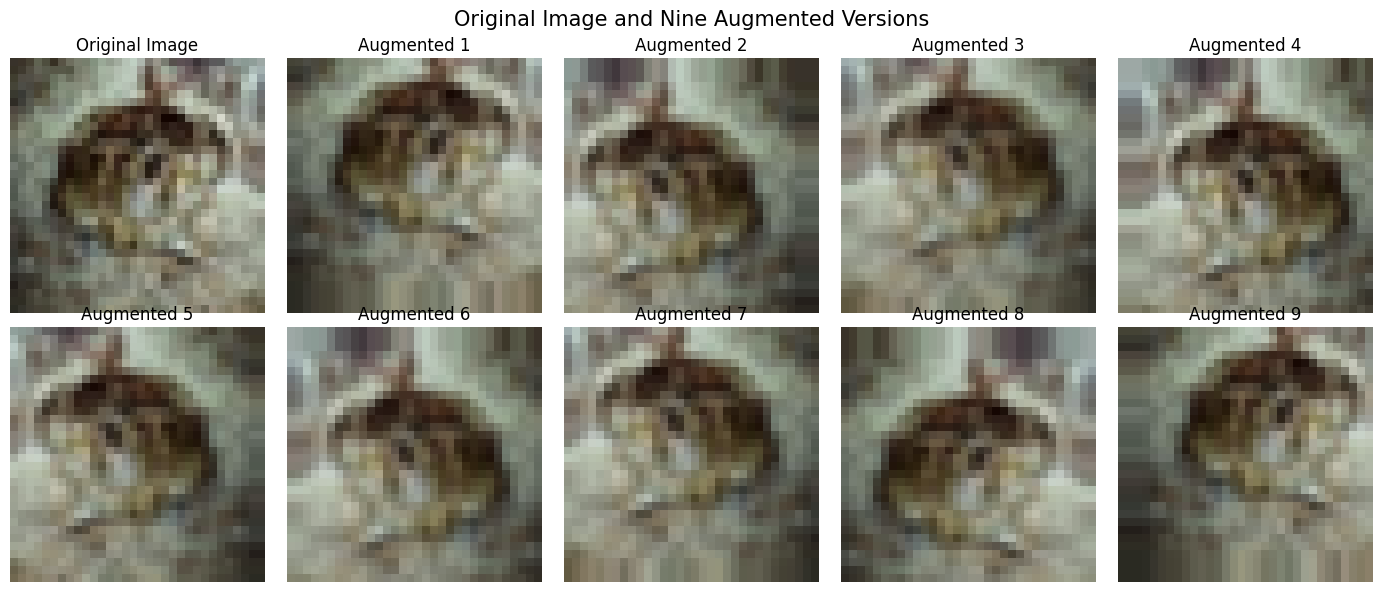

In [40]:


sample_image = x_train_task3[0]



sample_batch = np.expand_dims(sample_image, axis=0)



augmented_generator = train_datagen.flow(

    np.repeat(sample_batch, 9, axis=0),

    np.zeros(9),

    batch_size=9,

    shuffle=False,

    seed=SEED

)

augmented_images, _ = next(augmented_generator)

fig, axes = plt.subplots(2, 5, figsize=(14, 6))



axes[0, 0].imshow(sample_image)

axes[0, 0].set_title("Original Image")

axes[0, 0].axis('off')



for i in range(9):

    row = (i + 1) // 5

    col = (i + 1) % 5

    axes[row, col].imshow(augmented_images[i])

    axes[row, col].set_title(f"Augmented {i+1}")

    axes[row, col].axis('off')

plt.suptitle(
    "Original Image and Nine Augmented Versions",
    fontsize=15
)

plt.tight_layout()

plt.show()

**3(b) Training — With and Without Augmentation**

**Select the best CNN from Task 2**

In [49]:


import pandas as pd



if 'results_df' in globals() and not results_df.empty:

    task2_results = results_df

elif 'experiment_results' in globals() and len(experiment_results) > 0:

    task2_results = pd.DataFrame(experiment_results)

else:

    task2_results = None




if task2_results is not None:

    best_row_task2 = task2_results.loc[
        task2_results['Validation Accuracy'].idxmax()
    ]

    best_dropout = float(best_row_task2['Dropout'])

    best_batch_norm = bool(
        best_row_task2['Batch Normalization']
    )

    best_optimizer = str(
        best_row_task2['Optimizer']
    ).lower()

    best_batch_size = int(
        best_row_task2['Batch Size']
    )

    print("Best experimental CNN selected from Task 2.")


else:

    best_dropout = 0.0

    best_batch_norm = False

    best_optimizer = 'adam'

    best_batch_size = 32

    print("Task 2 experiment results not found.")

    print("Using Task 2(c) baseline CNN configuration.")




print("\nBEST CNN CONFIGURATION")

print("Dropout:", best_dropout)

print("Batch Normalization:", best_batch_norm)

print("Optimizer:", best_optimizer)

print("Batch Size:", best_batch_size)

Task 2 experiment results not found.
Using Task 2(c) baseline CNN configuration.

BEST CNN CONFIGURATION
Dropout: 0.0
Batch Normalization: False
Optimizer: adam
Batch Size: 32


**Create the best CNN architecture**

In [50]:
def build_task3_cnn():

    model_layers = [

        layers.Input(shape=(32, 32, 3))

    ]


    model_layers += [

        layers.Conv2D(
            32, (3, 3),
            activation='relu',
            padding='same'
        ),

        layers.MaxPooling2D((2, 2))

    ]

    if best_batch_norm:

        model_layers.append(
            layers.BatchNormalization()
        )

    if best_dropout > 0:

        model_layers.append(
            layers.Dropout(best_dropout)
        )



    model_layers += [

        layers.Conv2D(
            64, (3, 3),
            activation='relu',
            padding='same'
        ),

        layers.MaxPooling2D((2, 2))

    ]

    if best_batch_norm:

        model_layers.append(
            layers.BatchNormalization()
        )

    if best_dropout > 0:

        model_layers.append(
            layers.Dropout(best_dropout)
        )


    model_layers += [

        layers.Conv2D(
            128, (3, 3),
            activation='relu',
            padding='same'
        ),

        layers.MaxPooling2D((2, 2))

    ]

    if best_batch_norm:

        model_layers.append(
            layers.BatchNormalization()
        )

    if best_dropout > 0:

        model_layers.append(
            layers.Dropout(best_dropout)
        )



    model_layers += [

        layers.Flatten(),

        layers.Dense(128, activation='relu'),

        layers.Dense(10, activation='softmax')

    ]

    model = keras.Sequential(model_layers)


    if best_optimizer == 'adam':

        optimizer = keras.optimizers.Adam()

    elif best_optimizer == 'sgd':

        optimizer = keras.optimizers.SGD(learning_rate=0.001)

    elif best_optimizer == 'sgd_momentum':

        optimizer = keras.optimizers.SGD(
            learning_rate=0.001,
            momentum=0.9
        )

    elif best_optimizer == 'rmsprop':

        optimizer = keras.optimizers.RMSprop()

    else:

        raise ValueError("Unknown optimizer")

    model.compile(

        optimizer=optimizer,

        loss='categorical_crossentropy',

        metrics=['accuracy']

    )

    return model


print("Best CNN architecture function created.")

Best CNN architecture function created.


**Create training and validation generators**

In [51]:
# Generator without augmentation

no_aug_datagen = ImageDataGenerator(

    rescale=1./255

)

# Generator with standard augmentation

aug_datagen = ImageDataGenerator(

    rescale=1./255,

    horizontal_flip=True,

    width_shift_range=0.1,

    height_shift_range=0.1

)

# Validation generator

validation_datagen = ImageDataGenerator(

    rescale=1./255

)

# Test generator

testing_datagen = ImageDataGenerator(

    rescale=1./255

)

# Create non-augmented training generator

no_aug_train_generator = no_aug_datagen.flow(

    x_train_task3,

    y_train_task3,

    batch_size=best_batch_size,

    shuffle=True,

    seed=SEED

)

# Create augmented training generator

aug_train_generator = aug_datagen.flow(

    x_train_task3,

    y_train_task3,

    batch_size=best_batch_size,

    shuffle=True,

    seed=SEED

)

# Validation generator

validation_generator = validation_datagen.flow(

    x_val_task3,

    y_val_task3,

    batch_size=best_batch_size,

    shuffle=False

)

# Test generator

test_generator = testing_datagen.flow(

    x_test_raw,

    y_test_task3,

    batch_size=best_batch_size,

    shuffle=False

)

print("All generators created successfully.")

All generators created successfully.


**Create epoch timer**

In [52]:
class Task3Timer(keras.callbacks.Callback):

    def on_train_begin(self, logs=None):

        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):

        self.start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):

        elapsed = time.time() - self.start_time

        self.epoch_times.append(elapsed)


print("Epoch timer created.")

Epoch timer created.


**Train CNN without augmentation**

In [59]:


import tensorflow as tf

def build_task3_cnn():


    L = tf.keras.layers

    model_layers = [

        L.Input(shape=(32, 32, 3))

    ]

    model_layers += [

        L.Conv2D(32, (3, 3),
                 activation='relu',
                 padding='same'),

        L.MaxPooling2D((2, 2))

    ]

    if best_batch_norm:
        model_layers.append(L.BatchNormalization())

    if best_dropout > 0:
        model_layers.append(L.Dropout(best_dropout))

    model_layers += [

        L.Conv2D(64, (3, 3),
                 activation='relu',
                 padding='same'),

        L.MaxPooling2D((2, 2))

    ]

    if best_batch_norm:
        model_layers.append(L.BatchNormalization())

    if best_dropout > 0:
        model_layers.append(L.Dropout(best_dropout))

    model_layers += [

        L.Conv2D(128, (3, 3),
                 activation='relu',
                 padding='same'),

        L.MaxPooling2D((2, 2))

    ]

    if best_batch_norm:
        model_layers.append(L.BatchNormalization())

    if best_dropout > 0:
        model_layers.append(L.Dropout(best_dropout))

    model_layers += [

        L.Flatten(),

        L.Dense(128, activation='relu'),

        L.Dense(10, activation='softmax')

    ]

    model = tf.keras.Sequential(model_layers)

    if best_optimizer == 'adam':

        optimizer = tf.keras.optimizers.Adam()

    elif best_optimizer == 'sgd':

        optimizer = tf.keras.optimizers.SGD(
            learning_rate=0.001
        )

    elif best_optimizer == 'sgd_momentum':

        optimizer = tf.keras.optimizers.SGD(
            learning_rate=0.001,
            momentum=0.9
        )

    elif best_optimizer == 'rmsprop':

        optimizer = tf.keras.optimizers.RMSprop()

    else:
        raise ValueError("Unknown optimizer: " + best_optimizer)


    model.compile(

        optimizer=optimizer,

        loss='categorical_crossentropy',

        metrics=['accuracy']

    )

    return model


print("CNN architecture function created successfully!")

CNN architecture function created successfully!


**Evaluate CNN without augmentation**

In [64]:
# TASK 3(b): Train and Evaluate CNN WITHOUT Augmentation

import tensorflow as tf
import numpy as np
import time

from tensorflow.keras.preprocessing.image import ImageDataGenerator


required_variables = [
    'x_train_task3',
    'y_train_task3',
    'x_val_task3',
    'y_val_task3',
    'x_test_raw',
    'y_test_task3'
]

for variable in required_variables:
    if variable not in globals():
        raise ValueError(
            f"{variable} is missing. Run Task 3 Cells 2-5 first."
        )

SEED = 42
tf.keras.utils.set_random_seed(SEED)


best_dropout = globals().get('best_dropout', 0.0)
best_batch_norm = globals().get('best_batch_norm', False)
best_optimizer = globals().get('best_optimizer', 'adam')
best_batch_size = globals().get('best_batch_size', 32)

def build_task3_cnn():

    L = tf.keras.layers

    model_layers = [

        L.Input(shape=(32, 32, 3)),

        L.Conv2D(32, (3, 3),
                 activation='relu',
                 padding='same'),

        L.MaxPooling2D((2, 2))

    ]

    if best_batch_norm:
        model_layers.append(L.BatchNormalization())

    if best_dropout > 0:
        model_layers.append(L.Dropout(best_dropout))

    model_layers += [

        L.Conv2D(64, (3, 3),
                 activation='relu',
                 padding='same'),

        L.MaxPooling2D((2, 2))

    ]

    if best_batch_norm:
        model_layers.append(L.BatchNormalization())

    if best_dropout > 0:
        model_layers.append(L.Dropout(best_dropout))

    model_layers += [

        L.Conv2D(128, (3, 3),
                 activation='relu',
                 padding='same'),

        L.MaxPooling2D((2, 2))

    ]

    if best_batch_norm:
        model_layers.append(L.BatchNormalization())

    if best_dropout > 0:
        model_layers.append(L.Dropout(best_dropout))

    model_layers += [

        L.Flatten(),

        L.Dense(128, activation='relu'),

        L.Dense(10, activation='softmax')

    ]

    model = tf.keras.Sequential(model_layers)


    if best_optimizer == 'adam':
        optimizer = tf.keras.optimizers.Adam()

    elif best_optimizer == 'sgd':
        optimizer = tf.keras.optimizers.SGD(learning_rate=0.001)

    elif best_optimizer == 'sgd_momentum':
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=0.001,
            momentum=0.9
        )

    elif best_optimizer == 'rmsprop':
        optimizer = tf.keras.optimizers.RMSprop()

    else:
        raise ValueError("Unknown optimizer")

    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


no_aug_datagen = ImageDataGenerator(rescale=1./255)

val_datagen = ImageDataGenerator(rescale=1./255)

no_aug_train_generator = no_aug_datagen.flow(
    x_train_task3,
    y_train_task3,
    batch_size=best_batch_size,
    shuffle=True,
    seed=SEED
)

validation_generator = val_datagen.flow(
    x_val_task3,
    y_val_task3,
    batch_size=best_batch_size,
    shuffle=False
)

# Normalize test images
x_test_normalized = (
    x_test_raw.astype('float32') / 255.0
)


cnn_without_aug = build_task3_cnn()

cnn_without_aug.summary()

# Timer
class Task3Timer(tf.keras.callbacks.Callback):

    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.epoch_times.append(
            time.time() - self.start_time
        )


timer_without_aug = Task3Timer()


history_without_aug = cnn_without_aug.fit(

    no_aug_train_generator,

    validation_data=validation_generator,

    epochs=20,

    callbacks=[timer_without_aug],

    verbose=1

)


without_aug_test_loss, without_aug_test_acc = (
    cnn_without_aug.evaluate(
        x_test_normalized,
        y_test_task3,
        verbose=1
    )
)

without_aug_train_acc = (
    history_without_aug.history['accuracy'][-1]
)

without_aug_val_acc = (
    history_without_aug.history['val_accuracy'][-1]
)


without_aug_time = np.mean(
    timer_without_aug.epoch_times
)


print("\n===== CNN WITHOUT AUGMENTATION =====")

print("Training Accuracy:", without_aug_train_acc)

print("Validation Accuracy:", without_aug_val_acc)

print("Test Accuracy:", without_aug_test_acc)

print("Test Loss:", without_aug_test_loss)

print("Average Time Per Epoch:", without_aug_time)

print("\nCNN training and evaluation completed successfully!")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - accuracy: 0.4911 - loss: 1.4048 - val_accuracy: 0.6060 - val_loss: 1.1251
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.6532 - loss: 0.9831 - val_accuracy: 0.6762 - val_loss: 0.9183
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.7129 - loss: 0.8185 - val_accuracy: 0.6911 - val_loss: 0.9017
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.7520 - loss: 0.7099 - val_accuracy: 0.6970 - val_loss: 0.8776
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.7838 - loss: 0.6127 - val_accuracy: 0.7132 - val_loss: 0.8432
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.8156 - loss: 0.5269 - val_accuracy: 0.7089 - val_loss: 0.8720
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.8413 - loss: 0.4509 - val_accuracy: 0.7261 - val_loss: 0.8456
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - accuracy: 0.8637 - loss: 0.3823 

**Train CNN with augmentation**

In [67]:


tf.keras.utils.set_random_seed(SEED)



cnn_with_aug = build_task3_cnn()



cnn_with_aug.summary()


timer_with_aug = Task3Timer()


history_with_aug = cnn_with_aug.fit(

    aug_train_generator,

    validation_data=validation_generator,

    epochs=20,

    callbacks=[timer_with_aug],

    verbose=1

)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 36s 27ms/step - accuracy: 0.4437 - loss: 1.5229 - val_accuracy: 0.5943 - val_loss: 1.1444
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 29s 23ms/step - accuracy: 0.5874 - loss: 1.1567 - val_accuracy: 0.6255 - val_loss: 1.0707
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 29s 23ms/step - accuracy: 0.6383 - loss: 1.0199 - val_accuracy: 0.6867 - val_loss: 0.9221
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 28s 22ms/step - accuracy: 0.6753 - loss: 0.9240 - val_accuracy: 0.7018 - val_loss: 0.8615
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 27s 22ms/step - accuracy: 0.6998 - loss: 0.8588 - val_accuracy: 0.7238 - val_loss: 0.7876
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 28s 22ms/step - accuracy: 0.7174 - loss: 0.8098 - val_accuracy: 0.7232 - val_loss: 0.8057
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 28s 22ms/step - accuracy: 0.7291 - loss: 0.7745 - val_accuracy: 0.7407 - val_loss: 0.7523
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 28s 22ms/step - accuracy: 0.7412 -

**Evaluate CNN with augmentation**

In [68]:


with_aug_test_loss, with_aug_test_acc = (
    cnn_with_aug.evaluate(
        test_generator,
        verbose=1
    )
)



with_aug_train_acc = (
    history_with_aug.history['accuracy'][-1]
)


with_aug_val_acc = (
    history_with_aug.history['val_accuracy'][-1]
)



with_aug_time = np.mean(
    timer_with_aug.epoch_times
)

print("CNN WITH AUGMENTATION")

print("Training Accuracy:", with_aug_train_acc)

print("Validation Accuracy:", with_aug_val_acc)

print("Test Accuracy:", with_aug_test_acc)

print("Test Loss:", with_aug_test_loss)

print("Average Time Per Epoch:", with_aug_time)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7929 - loss: 0.6367
CNN WITH AUGMENTATION
Training Accuracy: 0.81045001745224
Validation Accuracy: 0.7918999791145325
Test Accuracy: 0.792900025844574
Test Loss: 0.6367279887199402
Average Time Per Epoch: 28.200913190841675


# 3(c) Comparison and Additional Augmentation

**Plot training and validation accuracy of both models**

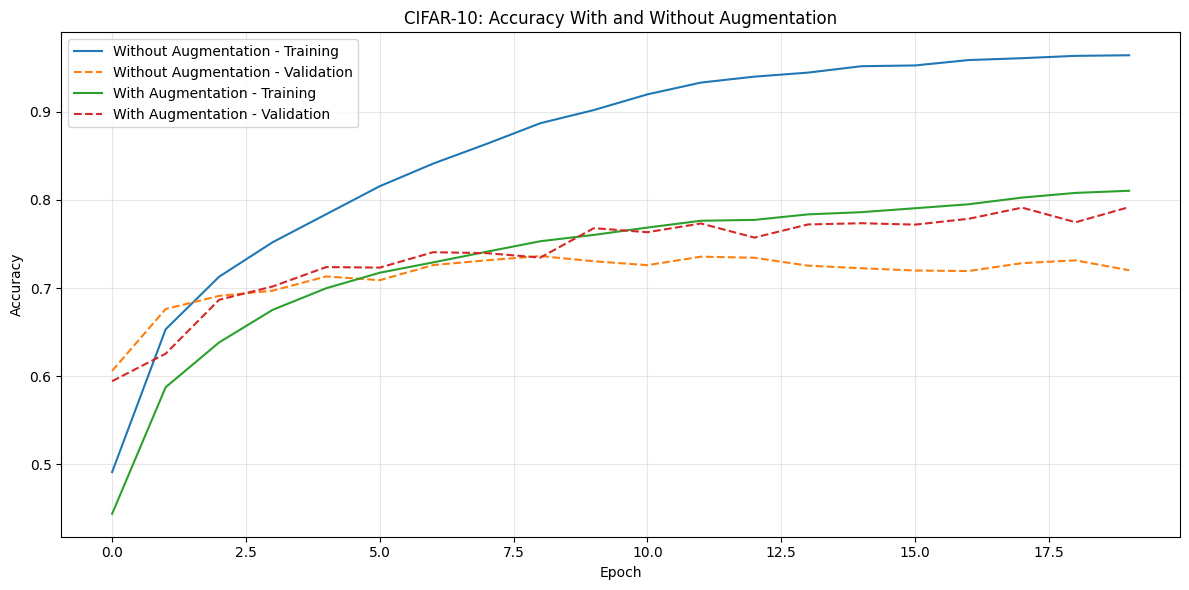

In [69]:
plt.figure(figsize=(12, 6))


plt.plot(

    history_without_aug.history['accuracy'],

    label='Without Augmentation - Training',

    linestyle='-'

)

plt.plot(

    history_without_aug.history['val_accuracy'],

    label='Without Augmentation - Validation',

    linestyle='--'

)


plt.plot(

    history_with_aug.history['accuracy'],

    label='With Augmentation - Training',

    linestyle='-'

)

plt.plot(

    history_with_aug.history['val_accuracy'],

    label='With Augmentation - Validation',

    linestyle='--'

)

plt.title("CIFAR-10: Accuracy With and Without Augmentation")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

**Compare overfitting gap and test accuracy**

In [70]:


without_aug_gap = (
    without_aug_train_acc - without_aug_val_acc
)

with_aug_gap = (
    with_aug_train_acc - with_aug_val_acc
)


augmentation_comparison = pd.DataFrame({

    'Model': [

        'Without Augmentation',

        'With Augmentation'

    ],

    'Training Accuracy': [

        without_aug_train_acc,

        with_aug_train_acc

    ],

    'Validation Accuracy': [

        without_aug_val_acc,

        with_aug_val_acc

    ],

    'Test Accuracy': [

        without_aug_test_acc,

        with_aug_test_acc

    ],

    'Overfitting Gap': [

        without_aug_gap,

        with_aug_gap

    ],

    'Time Per Epoch': [

        without_aug_time,

        with_aug_time

    ]

})

display(augmentation_comparison.round(4))

,Model,Training Accuracy,Validation Accuracy,Test Accuracy,Overfitting Gap,Time Per Epoch
0,Without Augmentation,0.9643,0.7202,0.7199,0.2441,8.7457
1,With Augmentation,0.8105,0.7919,0.7929,0.0186,28.2009


**Add rotation and zoom to augmentation pipeline**

In [71]:


rotation_zoom_datagen = ImageDataGenerator(

    rescale=1./255,

    horizontal_flip=True,

    width_shift_range=0.1,

    height_shift_range=0.1,

    rotation_range=15,

    zoom_range=0.1

)

print("Rotation and Zoom augmentation pipeline created.")

Rotation and Zoom augmentation pipeline created.


**Display rotation and zoom examples**

In [ ]:


sample_image = x_train_task3[1]

sample_batch = np.expand_dims(sample_image, axis=0)



rotation_generator = rotation_zoom_datagen.flow(

    np.repeat(sample_batch, 9, axis=0),

    np.zeros(9),

    batch_size=9,

    shuffle=False,

    seed=SEED

)

rotation_images, _ = next(rotation_generator)



fig, axes = plt.subplots(2, 5, figsize=(14, 6))

axes[0, 0].imshow(sample_image)

axes[0, 0].set_title("Original")

axes[0, 0].axis('off')

for i in range(9):

    row = (i + 1) // 5

    col = (i + 1) % 5

    axes[row, col].imshow(rotation_images[i])

    axes[row, col].set_title(f"Transformed {i+1}")

    axes[row, col].axis('off')

plt.suptitle(
    "CIFAR-10 Images with Rotation and Zoom",
    fontsize=15
)

plt.tight_layout()

plt.show()

**Create rotation and zoom training generator**

In [72]:


rotation_zoom_train_generator = rotation_zoom_datagen.flow(

    x_train_task3,

    y_train_task3,

    batch_size=best_batch_size,

    shuffle=True,

    seed=SEED

)

print("Rotation and Zoom training generator ready.")

Rotation and Zoom training generator ready.


**Train CNN with rotation and zoom**

In [73]:

tf.keras.utils.set_random_seed(SEED)



cnn_rotation_zoom = build_task3_cnn()



timer_rotation_zoom = Task3Timer()


history_rotation_zoom = cnn_rotation_zoom.fit(

    rotation_zoom_train_generator,

    validation_data=validation_generator,

    epochs=20,

    callbacks=[timer_rotation_zoom],

    verbose=1

)

Epoch 1/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 32s 24ms/step - accuracy: 0.4323 - loss: 1.5499 - val_accuracy: 0.5591 - val_loss: 1.2915
Epoch 2/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 29s 23ms/step - accuracy: 0.5706 - loss: 1.2002 - val_accuracy: 0.6428 - val_loss: 1.0248
Epoch 3/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 29s 23ms/step - accuracy: 0.6226 - loss: 1.0661 - val_accuracy: 0.6705 - val_loss: 0.9427
Epoch 4/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 28s 22ms/step - accuracy: 0.6524 - loss: 0.9892 - val_accuracy: 0.6813 - val_loss: 0.9229
Epoch 5/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 29s 23ms/step - accuracy: 0.6736 - loss: 0.9262 - val_accuracy: 0.6726 - val_loss: 0.9634
Epoch 6/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 28s 22ms/step - accuracy: 0.6905 - loss: 0.8849 - val_accuracy: 0.7357 - val_loss: 0.7658
Epoch 7/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 28s 22ms/step - accuracy: 0.7056 - loss: 0.8394 - val_accuracy: 0.6733 - val_loss: 1.0008
Epoch 8/20
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 28s 22ms/step - accuracy: 0.7165 -

**Evaluate rotation and zoom model**

In [74]:


rotation_test_loss, rotation_test_acc = (
    cnn_rotation_zoom.evaluate(
        test_generator,
        verbose=1
    )
)



rotation_train_acc = (
    history_rotation_zoom.history['accuracy'][-1]
)



rotation_val_acc = (
    history_rotation_zoom.history['val_accuracy'][-1]
)


rotation_time = np.mean(
    timer_rotation_zoom.epoch_times
)

print("CNN WITH ROTATION AND ZOOM")

print("Training Accuracy:", rotation_train_acc)

print("Validation Accuracy:", rotation_val_acc)

print("Test Accuracy:", rotation_test_acc)

print("Test Loss:", rotation_test_loss)

print("Average Time Per Epoch:", rotation_time)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7679 - loss: 0.6778
CNN WITH ROTATION AND ZOOM
Training Accuracy: 0.7817749977111816
Validation Accuracy: 0.7749000191688538
Test Accuracy: 0.7678999900817871
Test Loss: 0.6778297424316406
Average Time Per Epoch: 29.10766236782074


**Compare all three models**

In [75]:


rotation_gap = rotation_train_acc - rotation_val_acc



final_augmentation_results = pd.DataFrame({

    'Model': [

        'Without Augmentation',

        'Standard Augmentation',

        'Augmentation + Rotation + Zoom'

    ],

    'Training Accuracy': [

        without_aug_train_acc,

        with_aug_train_acc,

        rotation_train_acc

    ],

    'Validation Accuracy': [

        without_aug_val_acc,

        with_aug_val_acc,

        rotation_val_acc

    ],

    'Test Accuracy': [

        without_aug_test_acc,

        with_aug_test_acc,

        rotation_test_acc

    ],

    'Overfitting Gap': [

        without_aug_gap,

        with_aug_gap,

        rotation_gap

    ],

    'Time Per Epoch': [

        without_aug_time,

        with_aug_time,

        rotation_time

    ]

})

display(final_augmentation_results.round(4))

,Model,Training Accuracy,Validation Accuracy,Test Accuracy,Overfitting Gap,Time Per Epoch
0,Without Augmentation,0.9643,0.7202,0.7199,0.2441,8.7457
1,Standard Augmentation,0.8105,0.7919,0.7929,0.0186,28.2009
2,Augmentation + Rotation + Zoom,0.7818,0.7749,0.7679,0.0069,29.1077


Plot accuracy comparison of all three models

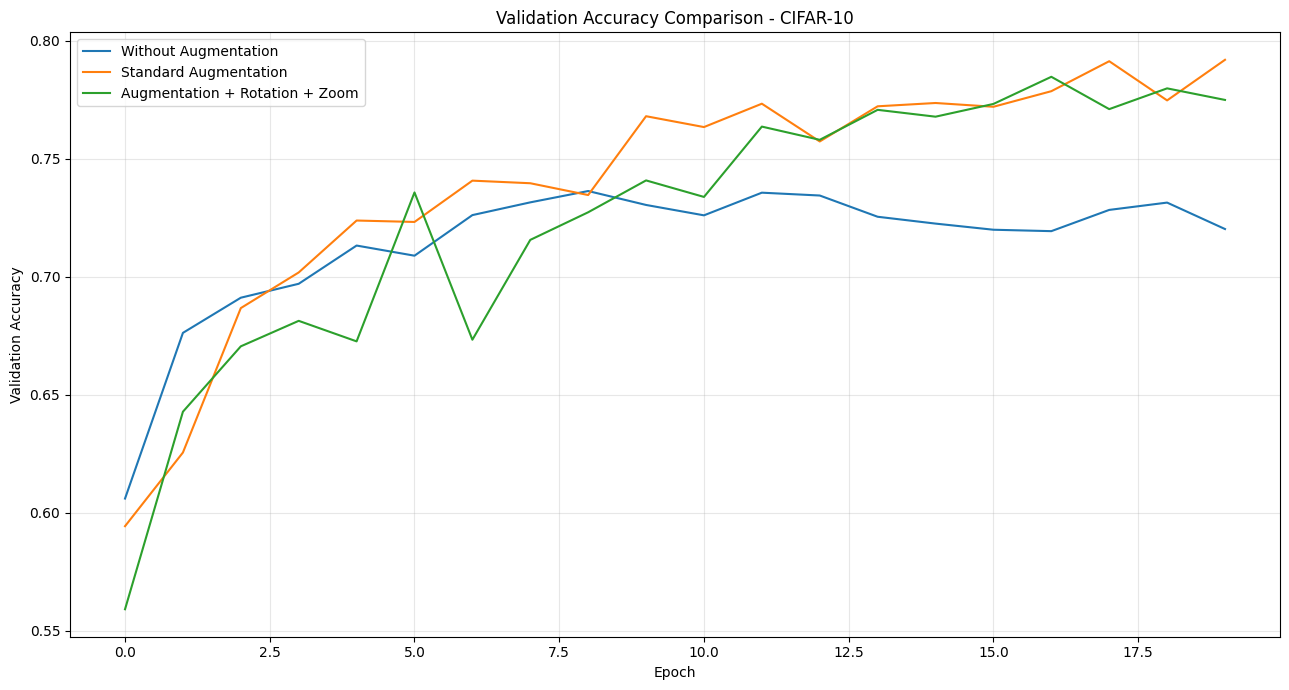

In [76]:
plt.figure(figsize=(13, 7))


plt.plot(
    history_without_aug.history['val_accuracy'],
    label='Without Augmentation'
)


plt.plot(
    history_with_aug.history['val_accuracy'],
    label='Standard Augmentation'
)


plt.plot(
    history_rotation_zoom.history['val_accuracy'],
    label='Augmentation + Rotation + Zoom'
)

plt.title("Validation Accuracy Comparison - CIFAR-10")

plt.xlabel("Epoch")

plt.ylabel("Validation Accuracy")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

**Plot training and validation loss**

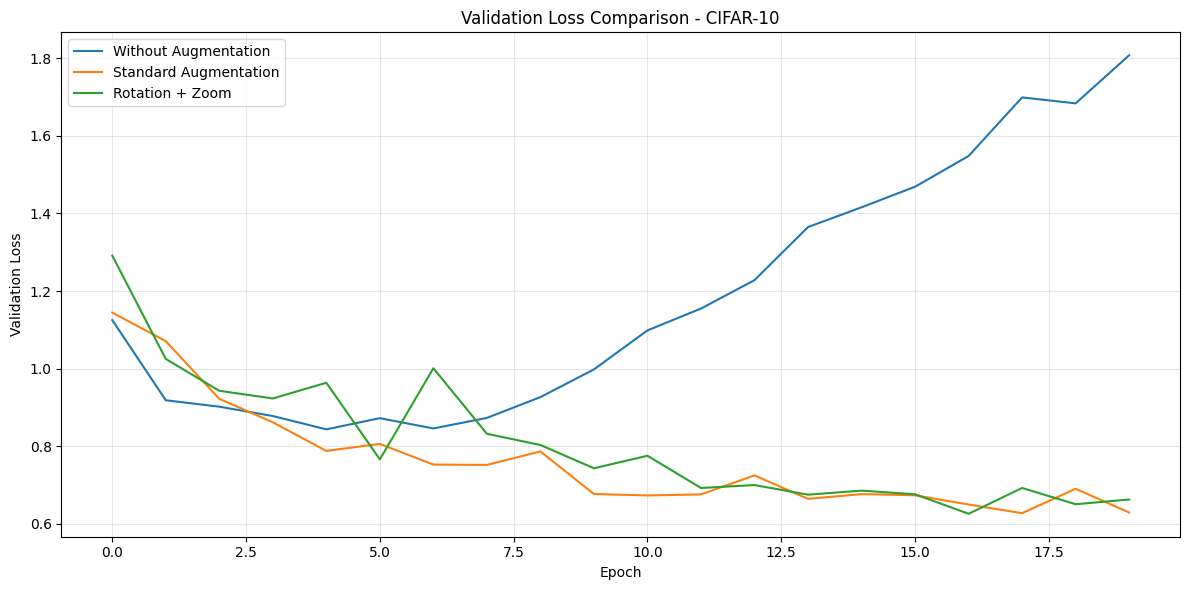

In [77]:
plt.figure(figsize=(12, 6))



plt.plot(
    history_without_aug.history['val_loss'],
    label='Without Augmentation'
)



plt.plot(
    history_with_aug.history['val_loss'],
    label='Standard Augmentation'
)



plt.plot(
    history_rotation_zoom.history['val_loss'],
    label='Rotation + Zoom'
)

plt.title("Validation Loss Comparison - CIFAR-10")

plt.xlabel("Epoch")

plt.ylabel("Validation Loss")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

**Save comparison results as CSV**

In [78]:


final_augmentation_results.to_csv(

    'task3_augmentation_comparison.csv',

    index=False

)

print("Task 3 comparison CSV saved successfully.")

Task 3 comparison CSV saved successfully.


# 3(d) Discussion and Analysis
This section requires written explanations of three important concepts.

You can add the following Markdown cells to your Jupyter Notebook.
Cell 27 — Why does data augmentation act as a regularizer?
Answer:

Data augmentation acts as a regularization technique because it increases the diversity of training images without collecting additional real-world data.

It applies random transformations such as horizontal flipping, rotation, shifting and zooming to existing images. As a result, the CNN learns to recognize objects under different visual conditions rather than memorizing the exact training images.

The main benefits include:
1. Reduces overfitting: The model becomes less dependent on individual training examples.
2. Improves generalization: The model learns features that remain useful when images are slightly transformed.
3. Increases training diversity: Different versions of the same image provide additional training variations.
4. Improves robustness: The model can become more reliable when objects appear in different positions or orientations.
Therefore, augmentation can improve validation and test performance, although its effectiveness depends on the transformations used.

# Why can vertical flipping be harmful for CIFAR-10 but not for top-down fruit images?
**Answer:**

Vertical flipping is not suitable for every image classification problem because some objects have a natural orientation.

CIFAR-10:
- Many objects have recognizable upright orientations.
- Cars, trucks, ships and animals normally appear in specific orientations.
- Flipping these images vertically can create unrealistic examples.
- Such transformations may confuse the CNN and reduce classification accuracy.
Top-down fruit images:
- Fruits photographed from above generally have less dependence on an upright orientation.
- Rotating or flipping these images may preserve their important visual characteristics.
- Therefore, vertical flipping can be more acceptable for certain top-down fruit datasets.
However, augmentation should always match the actual image distribution and photographic viewpoint.

**Compare the experimental results**
Add this Markdown explanation:

Experimental comparison:

Three CNN configurations were evaluated on CIFAR-10:
1. CNN without augmentation.
2. CNN with horizontal flipping and width/height shifting.
3. CNN with horizontal flipping, shifting, rotation and zoom.
The models were trained for 20 epochs using the same training and validation samples.

The comparison considers training accuracy, validation accuracy, test accuracy and the difference between training and validation accuracy.

The best configuration should be identified using validation performance, while final test accuracy provides an independent measure of generalization.

**Generate automatic result interpretation**

In [79]:


best_test_index = final_augmentation_results[
    'Test Accuracy'
].idxmax()

best_test_model = final_augmentation_results.loc[
    best_test_index
]



best_gap_index = final_augmentation_results[
    'Overfitting Gap'
].abs().idxmin()

best_gap_model = final_augmentation_results.loc[
    best_gap_index
]

print("TASK 3 EXPERIMENTAL ANALYSIS")

print("\nBest Test Accuracy:")

print(best_test_model['Model'])

print(
    "Test Accuracy:",
    round(best_test_model['Test Accuracy'], 4)
)

print("\nSmallest Training-Validation Gap:")

print(best_gap_model['Model'])

print(
    "Accuracy Gap:",
    round(best_gap_model['Overfitting Gap'], 4)
)

print("\nFinal Comparison:")

display(final_augmentation_results.round(4))

TASK 3 EXPERIMENTAL ANALYSIS

Best Test Accuracy:
Standard Augmentation
Test Accuracy: 0.7929

Smallest Training-Validation Gap:
Augmentation + Rotation + Zoom
Accuracy Gap: 0.0069

Final Comparison:


,Model,Training Accuracy,Validation Accuracy,Test Accuracy,Overfitting Gap,Time Per Epoch
0,Without Augmentation,0.9643,0.7202,0.7199,0.2441,8.7457
1,Standard Augmentation,0.8105,0.7919,0.7929,0.0186,28.2009
2,Augmentation + Rotation + Zoom,0.7818,0.7749,0.7679,0.0069,29.1077


**Save Task 3 plots and augmented image grid**

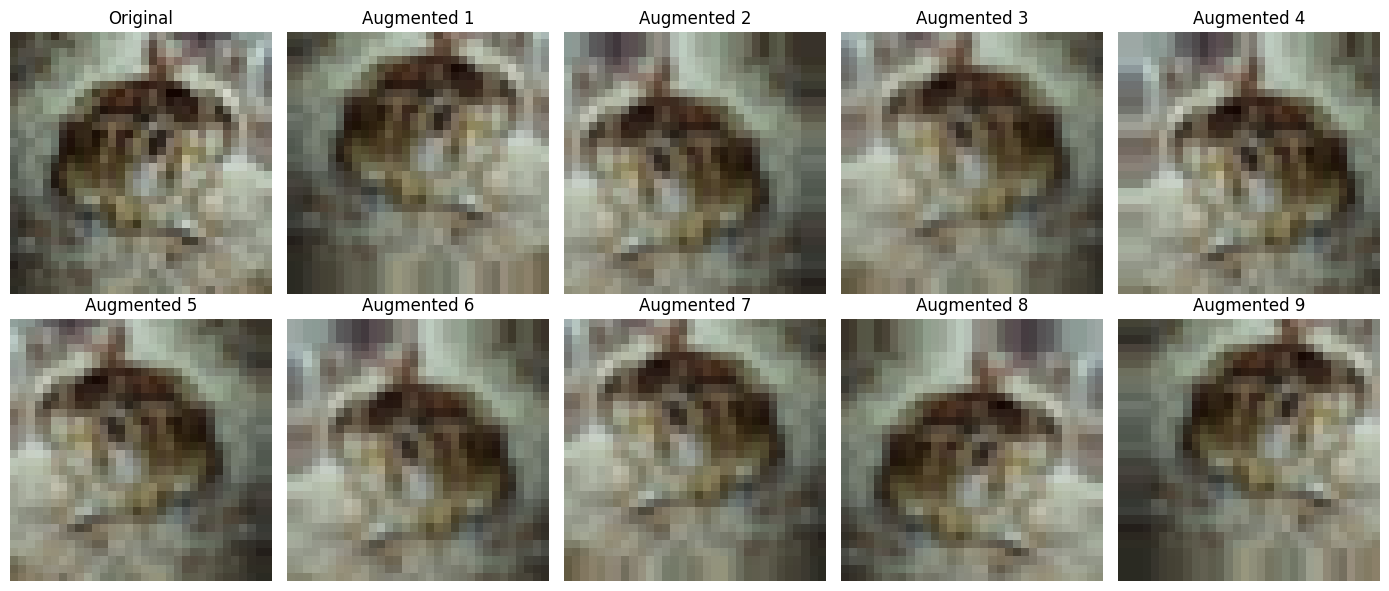

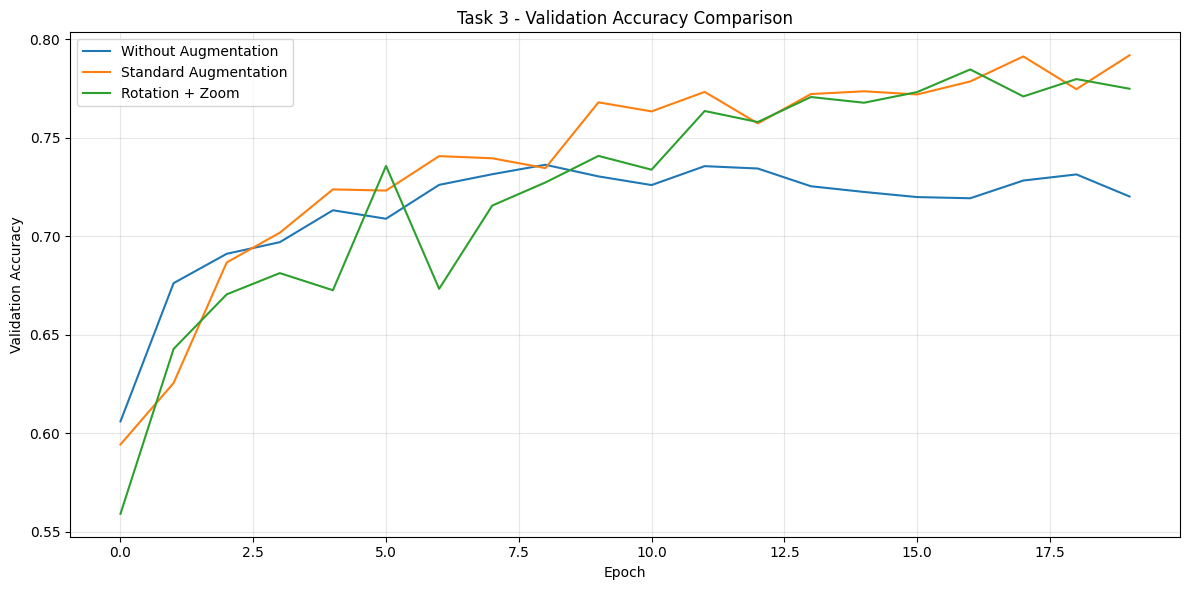

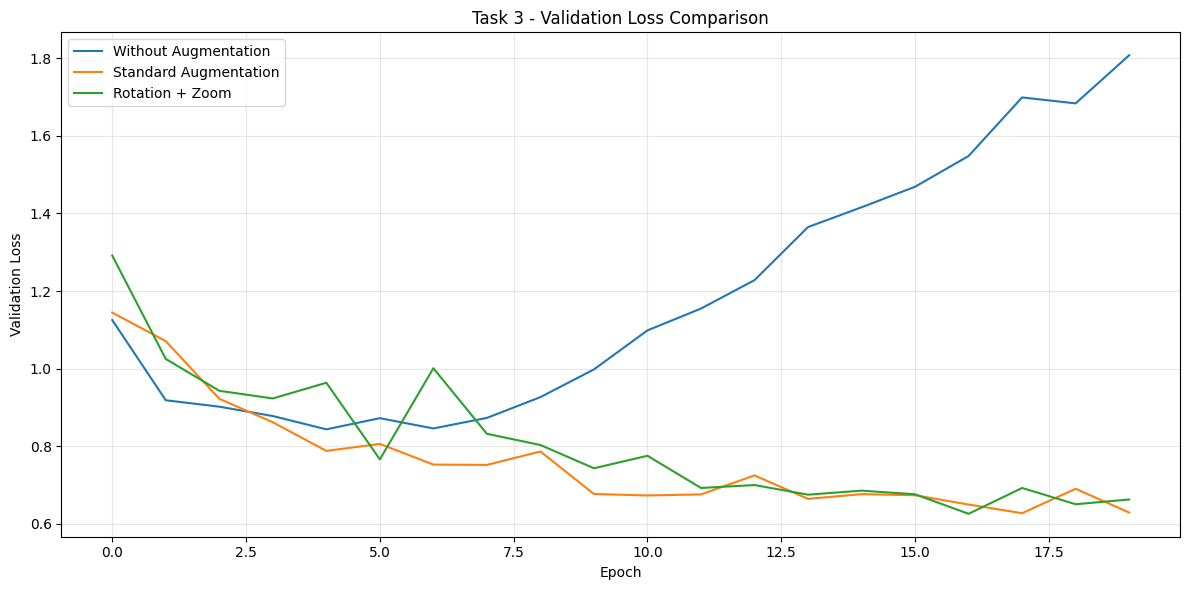

All Task 3 plots saved successfully.


In [80]:
import os

os.makedirs("Task3_Results", exist_ok=True)


fig, axes = plt.subplots(2, 5, figsize=(14, 6))

axes[0, 0].imshow(sample_image)
axes[0, 0].set_title("Original")
axes[0, 0].axis('off')

for i in range(9):

    row = (i + 1) // 5
    col = (i + 1) % 5

    axes[row, col].imshow(augmented_images[i])
    axes[row, col].set_title(f"Augmented {i+1}")
    axes[row, col].axis('off')

plt.tight_layout()

plt.savefig(
    "Task3_Results/augmented_images.png",
    dpi=200,
    bbox_inches='tight'
)

plt.show()


plt.figure(figsize=(12, 6))

plt.plot(
    history_without_aug.history['val_accuracy'],
    label='Without Augmentation'
)

plt.plot(
    history_with_aug.history['val_accuracy'],
    label='Standard Augmentation'
)

plt.plot(
    history_rotation_zoom.history['val_accuracy'],
    label='Rotation + Zoom'
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")

plt.title("Task 3 - Validation Accuracy Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Task3_Results/accuracy_comparison.png",
    dpi=200,
    bbox_inches='tight'
)

plt.show()



plt.figure(figsize=(12, 6))

plt.plot(
    history_without_aug.history['val_loss'],
    label='Without Augmentation'
)

plt.plot(
    history_with_aug.history['val_loss'],
    label='Standard Augmentation'
)

plt.plot(
    history_rotation_zoom.history['val_loss'],
    label='Rotation + Zoom'
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")

plt.title("Task 3 - Validation Loss Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Task3_Results/loss_comparison.png",
    dpi=200,
    bbox_inches='tight'
)

plt.show()

print("All Task 3 plots saved successfully.")

**Save trained models and CSV**

In [81]:

cnn_without_aug.save(
    "Task3_Results/cnn_without_augmentation.keras"
)

cnn_with_aug.save(
    "Task3_Results/cnn_with_augmentation.keras"
)

cnn_rotation_zoom.save(
    "Task3_Results/cnn_rotation_zoom.keras"
)



final_augmentation_results.to_csv(
    "Task3_Results/task3_final_comparison.csv",
    index=False
)

print("Task 3 models and results saved successfully.")

Task 3 models and results saved successfully.
